# Hand-View Grasp Classification: Original Version (Fall 2024)

**DATA 6610, final project** - Ryan Pinarija

This is my original course submission, kept **unchanged** for comparison. All outputs are from that run.
**The improved version is [`data6610_final_project-v2.ipynb`](data6610_final_project-v2.ipynb).**

**Task:** predict which of 5 grasp types a person would choose for an object (open palm, medium wrap, power sphere,
parallel extension, palmar pinch), using only the image from a camera on the hand. Data: the HANDS dataset (Han et al., 2020, Northeastern University).

**Original results (single split):** MobileNetV2 44.6% · Custom CNN 33.4% · ResNet50 33.3% test accuracy.

### Known issues, found in a later review and fixed in v2
- **Wrong input preprocessing:** the pretrained models received `/255` inputs instead of their required ImageNet preprocessing.
  ResNet50 and the custom CNN ended up near the **majority-class rate (~31%)**, meaning they learned close to nothing, and this wasn't recognized at the time.
- **Training setup:** the data wasn't shuffled (batches were in filename order), and the learning-rate schedule never triggered
  because its patience equaled early stopping's.
- **Model design:** the pretrained backbones were never fine-tuned, and the custom CNN's `Flatten` layer held 18.9M of its 19.2M parameters, so it overfit.
- **Data:** 64 blank images (failed segmentation in the dataset) were included, and 4 objects were split across two groups each,
  so some object views leaked between train and test.
- **Reproducibility:** the group shuffle had no seed, training loaded split files from an earlier run rather than the split printed below,
  cells were executed out of order, and the evaluation used a single split.
- **Leftover code:** unused imports (including a PyTorch import) and an unused `ModelCheckpoint` in each training cell.

**What held up:** the group-aware split, which keeps every view of an object in one split to prevent leakage, and MobileNetV2 as the strongest of the three models.

## Setup: imports

In [45]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.layers import Input
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

## 1. Load labels and map instances to object groups
Each range lists all orientations of one physical object, so they can be kept together in one split.

In [ ]:
# Load the CSV
df = pd.read_csv('Label_Complete.csv')  # Adjust the path to your CSV file

ranges = ['1-3', '4-6', '7-9', '10-13', '14-16', '17-19', '20-22', '23-26', '27-32', '33-36', '37-38', '39-40', '41-43', '44-48', '49-52', '53-57', '58-62',
          '63-65', '66', '67-69', '70-73', '74-78', '79-80', '81', '82-84', '85-90', '91-93', '94-100', '101-107', '108-112', '113-118', '119-121', '122-124',
          '125-128', '129-132', '133-136', '137-141', '142-144', '145-147', '148-149', '150-152', '153-155', '156-161', '162-164', '165-168', '169-171', 
          '172-174', '175-178', '179-181', '182-185', '186-187', '188-190', '191-192', '193-195', '196-197', '198-200', '201-204', '205-207', '208-213', 
          '214-219', '220-223', '224-226', '227-232', '233-235', '236-239', '240-242', '243-245', '246-251', '252-254', '255-258', '259-262', '263-264', 
          '265-268', '269-273', '274-279', '280-285', '286-291', '292-294', '295-299', '300-303', '304-306', '307-310', '311-314', '315-320', '321-326', 
          '327-329', '330-332', '333-337', '338-342', '343-346', '347-349', '350-352', '353-355', '356-359', '360-364', '365-368', '369-370', '371-374', 
          '375-379', '380-383', '384-388', '389-392', '393-396', '397-401', '402-403', '404-406', '407-413']


# Parse the ranges into object groups
groups = []
for r in ranges:
    if '-' in r:
        start, end = map(int, r.split('-'))
        groups.append(list(range(start, end + 1)))
    else:
        groups.append([int(r)])

# Flatten groups into a mapping of object ID to group ID
object_to_group = {}
for group_id, group in enumerate(groups):
    for obj_id in group:
        object_to_group[obj_id] = group_id

In [47]:
# Extract object IDs from the filenames
df['object_id'] = df['image_name'].apply(lambda x: int(x.split('_')[0][2:]))

# Map object IDs to group IDs
df['group_id'] = df['object_id'].map(object_to_group)

# Get unique group IDs
unique_groups = df['group_id'].unique()
np.random.shuffle(unique_groups)

## 2. Group-aware train / validation / test split
60 / 20 / 20 by object group, so no object appears in more than one split.

In [48]:
# Split groups into training, validation, and test sets
train_groups, temp_groups = train_test_split(unique_groups, test_size=0.4, random_state=42)
val_groups, test_groups = train_test_split(temp_groups, test_size=0.5, random_state=42)

# Assign splits based on group IDs
train_df = df[df['group_id'].isin(train_groups)]
val_df = df[df['group_id'].isin(val_groups)]
test_df = df[df['group_id'].isin(test_groups)]

# Verify the splits
print(f"Training set size: {len(train_df)} images, {len(train_df['group_id'].unique())} groups")
print(f"Validation set size: {len(val_df)} images, {len(val_df['group_id'].unique())} groups")
print(f"Test set size: {len(test_df)} images, {len(test_df['group_id'].unique())} groups")

Training set size: 2795 images, 64 groups
Validation set size: 859 images, 21 groups
Test set size: 812 images, 22 groups


In [49]:
train_df

,image_name,xmin,xmax,ymin,ymax,label,Unnamed: 6,Unnamed: 7,object_id,group_id
0,im100_1.jpg,734,1240,2,80,4,NaN,NaN,100,27
1,im101_1.jpg,391,877,99,289,3,NaN,NaN,101,28
2,im102_1.jpg,745,997,72,274,1,NaN,NaN,102,28
3,im103_1.jpg,352,864,754,934,2,NaN,NaN,103,28
4,im104_1.jpg,529,1109,672,888,2,NaN,NaN,104,28
...,...,...,...,...,...,...,...,...,...,...
4461,im96_11.jpg,937,1223,611,905,4,NaN,NaN,96,27
4462,im97_11.jpg,810,1064,538,874,4,NaN,NaN,97,27
4463,im98_11.jpg,424,884,295,679,4,NaN,NaN,98,27
4464,im99_11.jpg,423,1011,341,607,4,NaN,NaN,99,27


In [50]:
# # Save splits if needed
# train_df.to_csv('train_split.csv', index=False)
# val_df.to_csv('val_split.csv', index=False)
# test_df.to_csv('test_split.csv', index=False)

## 3. Model class, and MobileNetV2 (transfer learning)

In [ ]:
class HandMovementCNN:
    def __init__(self, 
                 input_shape=(224, 224, 3), 
                 num_classes=5, 
                 model_type='custom'):
        """
        Initialize CNN model for hand movement classification
        
        Args:
            input_shape (tuple): Input image dimensions
            num_classes (int): Number of hand movement classes
            model_type (str): 'custom', 'convnext', or 'resnet'
        """
        self.input_shape = input_shape
        self.num_classes = num_classes
        self.model_type = model_type
        self.model = None
    
    
    def build_custom_cnn(self):
        """
        Build a custom Convolutional Neural Network
        
        Returns:
            tensorflow.keras.Model: Compiled CNN model
        """
        model = models.Sequential([
            # First Convolutional Block
            Input(shape=self.input_shape),
            layers.Conv2D(32, (3, 3), activation='relu'),
            layers.Conv2D(32, (3, 3), activation='relu'),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            
            # Second Convolutional Block
            layers.Conv2D(64, (3, 3), activation='relu'),
            layers.Conv2D(64, (3, 3), activation='relu'),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),
            
            # Third Convolutional Block
            layers.Conv2D(128, (3, 3), activation='relu'),
            layers.Conv2D(128, (3, 3), activation='relu'),
            layers.BatchNormalization(),
            layers.MaxPooling2D((2, 2)),
            layers.Dropout(0.25),
            
            # Flatten and Dense Layers
            layers.Flatten(),
            layers.Dropout(0.5),
            layers.Dense(256, activation='relu'),
            layers.Dropout(0.5),
            
            # Output Layer
            layers.Dense(self.num_classes, activation='softmax')
        ])
        
        return model
    
    def build_transfer_learning_model(self):
        """
        Build a transfer learning model
        
        Returns:
            tensorflow.keras.Model: Compiled transfer learning model
        """
        if self.model_type == 'mobilenet':
            base_model = MobileNetV2(
                weights='imagenet', 
                include_top=False, 
                input_shape=self.input_shape
            )
        elif self.model_type == 'resnet':
            base_model = ResNet50(
                weights='imagenet', 
                include_top=False, 
                input_shape=self.input_shape
            )
        else:
            raise ValueError("Invalid model type. Choose 'mobilenet' or 'resnet'")
        
        # Freeze base model layers
        base_model.trainable = False
        
        # Add custom top layers
        model = models.Sequential([
            base_model,
            layers.GlobalAveragePooling2D(),
            layers.Dense(256, activation='relu'),
            layers.Dropout(0.5),
            layers.Dense(self.num_classes, activation='softmax')
        ])
        
        return model
    
    def compile_model(self, learning_rate=1e-4):
        """
        Compile the model with appropriate optimizer and metrics
        
        Args:
            learning_rate (float): Initial learning rate
        """
        # Choose model based on type
        if self.model_type == 'custom':
            self.model = self.build_custom_cnn()
        else:
            self.model = self.build_transfer_learning_model()
        
        # Compile model
        self.model.compile(
            optimizer=optimizers.Adam(learning_rate=learning_rate),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy']
        )
        
        # Print model summary
        self.model.summary()
    
    def load_datasets(self, train_df, val_df, test_df, image_dir, batch_size=32, target_size=(224, 224)):
        """
        Load train, validation, and test datasets from DataFrames

        Args:
            train_df (pd.DataFrame): Training data DataFrame
            val_df (pd.DataFrame): Validation data DataFrame
            test_df (pd.DataFrame): Test data DataFrame
            image_dir (str): Path to directory containing images
            batch_size (int): Number of images per batch
            target_size (tuple): Resize images to this size

        Returns:
            tuple: (train_dataset, val_dataset, test_dataset)
        """
        def preprocess_image_and_label(row):
            """Helper function to preprocess image and label."""
            img_path = os.path.join(image_dir, row['image_name'])
            # Load image
            img = tf.keras.utils.load_img(img_path, target_size=target_size)
            img = tf.keras.utils.img_to_array(img) / 255.0  # Normalize to [0, 1]

            return img, row['label']

        def create_dataset(df):
            """Create TensorFlow dataset from DataFrame."""
            images = []
            labels = []
            for _, row in df.iterrows():
                img, label = preprocess_image_and_label(row)
                images.append(img)
                labels.append(label)

            images = tf.convert_to_tensor(images)
            labels = tf.convert_to_tensor(labels)
            dataset = tf.data.Dataset.from_tensor_slices((images, labels))
            return dataset.batch(batch_size)

        # Create datasets for train, validation, and test
        train_dataset = create_dataset(train_df)
        val_dataset = create_dataset(val_df)
        test_dataset = create_dataset(test_df)
    
        return train_dataset, val_dataset, test_dataset
    
    def train_model(self, 
                    train_dataset,
                    val_dataset, 
                    epochs=50, 
                    patience=10):
        """
        Train the model with early stopping and learning rate reduction
        
        Args:
            train_dataset (Dataset): Training dataset
            val_dataset (Dataset): Validation dataset
            epochs (int): Maximum number of training epochs
            patience (int): Patience for early stopping
        
        Returns:
            History object from model training
        """
        # Callbacks
        checkpoint = ModelCheckpoint(
            'best_model.keras', 
            save_best_only=True, 
            monitor='val_loss'
        )
        
        early_stopping = EarlyStopping(
            monitor='val_loss', 
            patience=patience, 
            restore_best_weights=True
        )
        
        reduce_lr = ReduceLROnPlateau(
            monitor='val_loss', 
            factor=0.1, 
            patience=10
        )
        
        # Train model
        history = self.model.fit(
            train_dataset,
            validation_data=val_dataset,
            epochs=epochs,
            callbacks=[checkpoint, early_stopping, reduce_lr]
        )
        
        return history
    
    def evaluate_model(self, test_dataset):
        """
        Evaluate model performance on test set
        
        Args:
            test_dataset (Dataset): Test dataset
        
        Returns:
            tuple: Test loss and accuracy
        """
        loss, accuracy = self.model.evaluate(test_dataset)
        
        print(f"Test Loss: {loss}")
        print(f"Test Accuracy: {accuracy}")
        
        return loss, accuracy


if __name__ == "__main__":
    # Load DataFrames
    train_df = pd.read_csv('train_split.csv')
    val_df = pd.read_csv('val_split.csv')
    test_df = pd.read_csv('test_split.csv')
    
    image_dir = "Dataset_20181026/TrainingImages"  # Path to directory containing all images
    
    # Initialize CNN
    cnn = HandMovementCNN(
        input_shape=(224, 224, 3),  # For custom model
        num_classes=5,
        model_type='mobilenet'  # Options: 'custom', 'mobilenet', 'resnet'
    )
    
    # Compile model
    cnn.compile_model(learning_rate=1e-4)
    
    # Load datasets
    train_dataset, val_dataset, test_dataset = cnn.load_datasets(
        train_df=train_df,
        val_df=val_df,
        test_df=test_df,
        image_dir=image_dir,
        batch_size=32,
        # target_size=(256, 192)  # For custom model
        # target_size=(512, 384)  # For custom model
        target_size=(224, 224) # For transfer learning models
    )
    
    # Train model
    history = cnn.train_model(
        train_dataset,
        val_dataset,
        epochs=50,
        patience=10
    )
    
    # Evaluate on test set
    cnn.evaluate_model(test_dataset)

Model: "sequential_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_16     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,205 (9.87 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 39s 401ms/step - accuracy: 0.2958 - loss: 1.7023 - val_accuracy: 0.4667 - val_loss: 1.2899 - learning_rate: 1.0000e-04
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 29s 344ms/step - accuracy: 0.3924 - loss: 1.3818 - val_accuracy: 0.4727 - val_loss: 1.2657 - learning_rate: 1.0000e-04
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 30s 351ms/step - accuracy: 0.4559 - loss: 1.2812 - val_accuracy: 0.4752 - val_loss: 1.2418 - learning_rate: 1.0000e-04
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 37s 444ms/step - accuracy: 0.4683 - loss: 1.2253 - val_accuracy: 0.4788 - val_loss: 1.2350 - learning_rate: 1.0000e-04
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 38s 456ms/step - accuracy: 0.4921 - loss: 1.2138 - val_accuracy: 0.4776 - val_loss: 1.2240 - learning_rate: 1.0000e-04
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 34s 405ms/step - accuracy: 0.5167 - loss: 1.1776 - val_accuracy: 0.4897 - val_loss: 1.2191 - learning_rate: 1.0000e-04
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 35s 417ms/step - acc

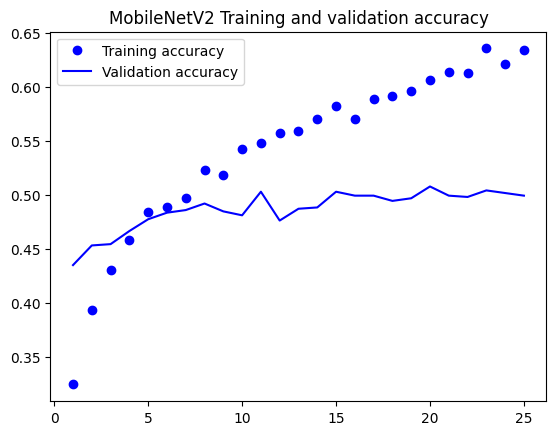

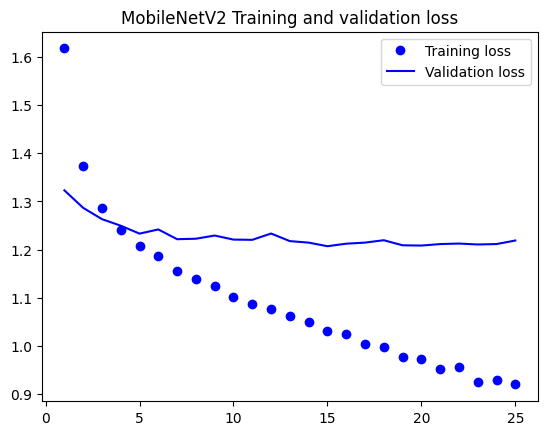

In [ ]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(accuracy) + 1)
plt.plot(epochs, accuracy, "bo", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("MobileNetV2 Training and validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("MobileNetV2 Training and validation loss")
plt.legend()
plt.show()

## 4. ResNet50 (transfer learning)

In [ ]:
if __name__ == "__main__":
    # Load DataFrames
    train_df = pd.read_csv('train_split.csv')
    val_df = pd.read_csv('val_split.csv')
    test_df = pd.read_csv('test_split.csv')
    
    image_dir = "Dataset_20181026/TrainingImages"  # Path to directory containing all images
    
    # Initialize CNN
    cnn = HandMovementCNN(
        input_shape=(224, 224, 3),  # For custom model
        num_classes=5,
        model_type='resnet'  # Options: 'custom', 'mobilenet', 'resnet'
    )
    
    # Compile model
    cnn.compile_model(learning_rate=1e-4)
    
    # Load datasets
    train_dataset, val_dataset, test_dataset = cnn.load_datasets(
        train_df=train_df,
        val_df=val_df,
        test_df=test_df,
        image_dir=image_dir,
        batch_size=32,
        # target_size=(256, 192)  # For custom model
        # target_size=(512, 384)  # For custom model
        target_size=(224, 224) # For transfer learning models
    )
    
    checkpoint = ModelCheckpoint(
            'resnet_best_model.keras', 
            save_best_only=True, 
            monitor='val_accuracy'
        )
    
    # Train model
    history = cnn.train_model(
        train_dataset,
        val_dataset,
        epochs=50,
        patience=10
    )
    
    # Evaluate on test set
    cnn.evaluate_model(test_dataset)

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_14     │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,113,541 (91.99 MB)

 Trainable params: 525,829 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 100s 1s/step - accuracy: 0.2446 - loss: 1.7574 - val_accuracy: 0.3030 - val_loss: 1.4298 - learning_rate: 1.0000e-04
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.2495 - loss: 1.5865 - val_accuracy: 0.2970 - val_loss: 1.4270 - learning_rate: 1.0000e-04
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - accuracy: 0.2523 - loss: 1.5204 - val_accuracy: 0.3139 - val_loss: 1.4244 - learning_rate: 1.0000e-04
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.2511 - loss: 1.4881 - val_accuracy: 0.3079 - val_loss: 1.4085 - learning_rate: 1.0000e-04
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.2667 - loss: 1.4757 - val_accuracy: 0.3224 - val_loss: 1.4108 - learning_rate: 1.0000e-04
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.2582 - loss: 1.4604 - val_accuracy: 0.3539 - val_loss: 1.4006 - learning_rate: 1.0000e-04
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.2719 - lo

In [44]:
cnn.evaluate_model(test_dataset)

31/31 ━━━━━━━━━━━━━━━━━━━━ 24s 774ms/step - accuracy: 0.3227 - loss: 1.3761
Test Loss: 1.3685874938964844
Test Accuracy: 0.3326488733291626


(1.3685874938964844, 0.3326488733291626)

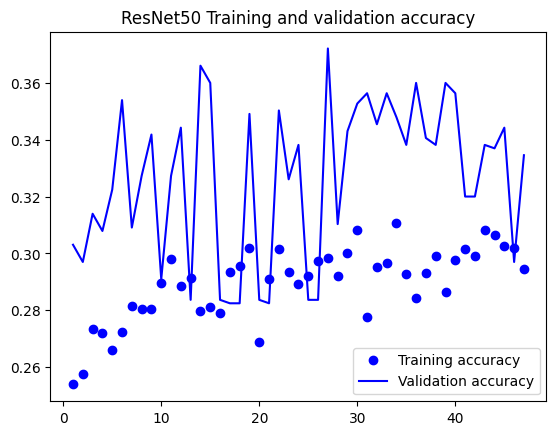

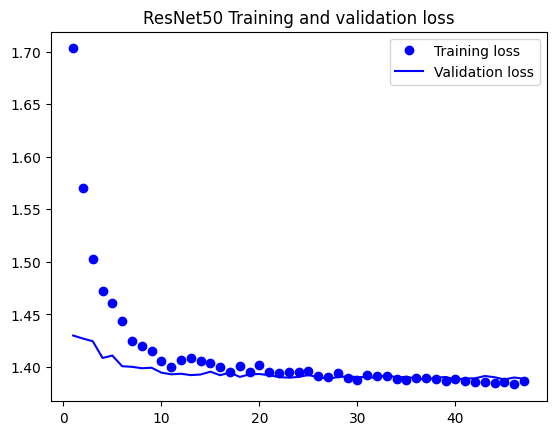

In [ ]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(accuracy) + 1)
plt.plot(epochs, accuracy, "bo", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("ResNet50 Training and validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("ResNet50 Training and validation loss")
plt.legend()
plt.show()

## 5. Custom CNN (trained from scratch)

In [ ]:
if __name__ == "__main__":
    # Load DataFrames
    train_df = pd.read_csv('train_split.csv')
    val_df = pd.read_csv('val_split.csv')
    test_df = pd.read_csv('test_split.csv')
    
    image_dir = "Dataset_20181026/TrainingImages"  # Path to directory containing all images
    
    # Initialize CNN
    cnn = HandMovementCNN(
        input_shape=(224, 224, 3),  # For custom model
        num_classes=5,
        model_type='custom'  # Options: 'custom', 'mobilenet', 'resnet'
    )
    
    # Compile model
    cnn.compile_model(learning_rate=1e-4)
    
    # Load datasets
    train_dataset, val_dataset, test_dataset = cnn.load_datasets(
        train_df=train_df,
        val_df=val_df,
        test_df=test_df,
        image_dir=image_dir,
        batch_size=32,
        target_size=(224, 224) 
    )
    
    checkpoint = ModelCheckpoint(
            'custom_best_model.keras', 
            save_best_only=True, 
            monitor='val_accuracy'
        )
    
    # Train model
    history = cnn.train_model(
        train_dataset,
        val_dataset,
        epochs=50,
        patience=10
    )
    
    # Evaluate on test set
    cnn.evaluate_model(test_dataset)

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 220, 220, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 110, 110, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 106, 106, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 106, 106, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 53, 53, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 53, 53, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 51, 51, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 49, 49, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 49, 49, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 73728)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 73728)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 256)            │    18,874,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,163,813 (73.10 MB)

 Trainable params: 19,163,365 (73.10 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.2808 - loss: 3.5997 - val_accuracy: 0.1624 - val_loss: 13.3325 - learning_rate: 1.0000e-04
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.2684 - loss: 1.5266 - val_accuracy: 0.1624 - val_loss: 21.2786 - learning_rate: 1.0000e-04
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.2919 - loss: 1.5246 - val_accuracy: 0.1624 - val_loss: 27.5700 - learning_rate: 1.0000e-04
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.3036 - loss: 1.4793 - val_accuracy: 0.1624 - val_loss: 25.6701 - learning_rate: 1.0000e-04
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.2986 - loss: 1.4594 - val_accuracy: 0.1624 - val_loss: 21.5169 - learning_rate: 1.0000e-04
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.3122 - loss: 1.4553 - val_accuracy: 0.1624 - val_loss: 19.2281 - learning_rate: 1.0000e-04
Epoch 7/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0

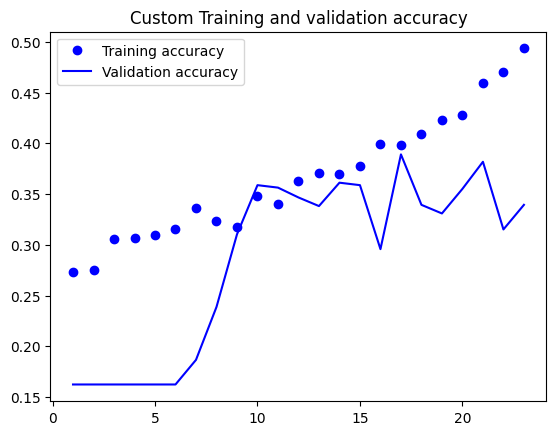

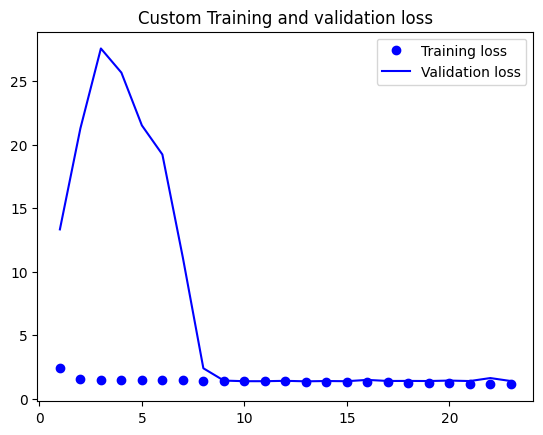

In [ ]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(accuracy) + 1)
plt.plot(epochs, accuracy, "bo", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("Custom Training and validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Custom Training and validation loss")
plt.legend()
plt.show()